# Visualizing Fire Scars from the 2025 Eaton and Palisades Fires
Author: Courtney Lorey \
Date: 2026-11-21

https://github.com/cllorey/eds220-hwk4.git


## About

### Purpose
The January 2025 Eaton and Palisades fires devastated more than 16,000 structures, forced over 200,000 residents to leave their homes, and inflicted severe ecological damage.

In this notebook we create a false color image of the January 2025 Eaton and Palisades Fires using remotely sensed data, exploring the fire scar (vegetation health, burn severity, and the extent) and highlighting how coding and data visualization support monitoring of wildfire impacts.

### Highlights
* Tabular data wrangling and exploration with geopandas
* NetCDF data wrangling and exploration with xarray and rioxarray
* Merging of multi-dimensional raster data and tabular vector data
* Creating and customizing a true and false color map

### Dataset Description
This analysis utilizes two datasets:

1) Landsat 8 satellite data
The first dataset is a simplified collection of bands (red, green, blue, near-infrared and shortwave infrared) from the Landsat Collection 2 Level-2 atmospherically corrected surface reflectance data, collected by the Landsat 8 satellite, retrieved from the [Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2) data catalog, and clipped to an area surrounding the fire perimeters.

2) Eaton and Palisades fire perimeters
The second dataset contains shapefiles of the Eaton and Palisades fire perimeters, retrieved from the [official LA County site](https://data.lacounty.gov/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about) 

### References 
County of Los Angeles. (2025). *Palisades and Eaton Dissolved Fire Perimeters* [Data set]. LA County Open Data. Retrieved November 19, 2026, from [https://data.lacounty.gov/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about](https://data.lacounty.gov/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about)

County of Los Angeles. (n.d.). *Data and recovery tools*. LA County Recovers. Retrieved November 19, 2026, from [https://recovery.lacounty.gov/data-recovery-tools/](https://recovery.lacounty.gov/data-recovery-tools/)

Microsoft Planetary Computer. (n.d.). *Landsat Collection 2 Level-2 atmospherically corrected surface reflectance data* [dataset]. Landsat Collection 2 Level-2. Retrieved November 19, 2026, from [https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2](https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2)

## Workflow

### Import packages

In [93]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import geopandas as gpd

import xarray as xr   

import rioxarray as rioxr

### Load & explore fire perimeter data

In [17]:
# Load Eaton perimeter shapefile
eaton = gpd.read_file(os.path.join('data',
                                   'Eaton_Perimeter_20250121',
                                   'Eaton_Perimeter_20250121.shp')
                                    )

# Load Palisades perimeter shapefile
palisades = gpd.read_file(os.path.join('data',
                                    'Palisades_Perimieter_20250121',
                                    'Palisades_Perimieter_20250121.shp')
                                    )

# Explore data
gdfs = {"eaton": eaton, 
        "palisades": palisades}

for name, df in gdfs.items():
    print(f"{name} shape: {df.shape}")
    print(f"{name} geometry: {type(df.geometry)}")
    print(f"{name} is Projected: {df.crs.is_projected}")
    print(f"{name} is Geographic: {df.crs.is_geographic}")
    print(f"{name} CRS: {df.crs}")

eaton shape: (1, 24)
eaton geometry: <class 'geopandas.geoseries.GeoSeries'>
eaton is Projected: False
eaton is Geographic: True
eaton CRS: EPSG:4269
palisades shape: (1, 24)
palisades geometry: <class 'geopandas.geoseries.GeoSeries'>
palisades is Projected: False
palisades is Geographic: True
palisades CRS: EPSG:4269


<Axes: >

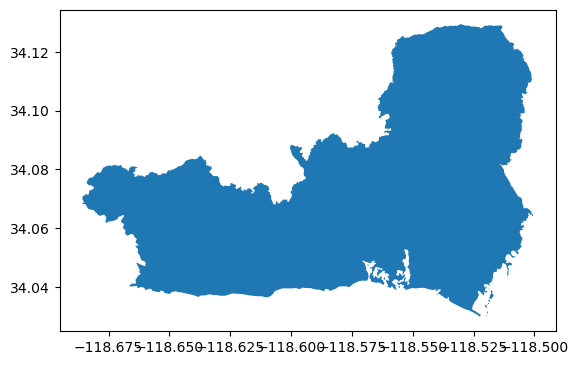

In [60]:
palisades.plot()

<Axes: >

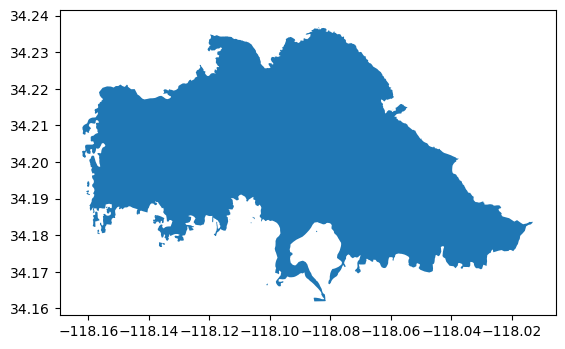

In [61]:
eaton.plot()

#### Summary

The Eaton and Palisades shapefiles are both geopandas geoseries with EPSG: 4269 as their coordinate reference system. They are both geographic, not projected. 

### Load & explore Landsat data

In [20]:
# Import NetCDF file
fp = os.path.join('data',
                  'landsat8-2025-02-23-palisades-eaton.nc')
landsat = xr.open_dataset(fp)
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

### Summary

This is an xarray dataset with variables 'red', 'green', 'blue', near-infrared ('nir08'), shortwave infrared ('swir22'), and spatial_ref. They are all float 32s except for 'spatial_ref', which is int64.

The dimensions of this dataset are (x:2742, y:1418), and coordinates are x and y coordinates of projection, measured in metres, with crs EPSG:32611 and a resolution of (x:30, y:-30). Datetime format is datetime64[ns]. 

Given the apparent difference in crs, will eventually need to reproject the perimeter shapefiles to match this crs (or vice versa). 

### Restoring geospatial information

In [26]:
# Check the CRS 
print('landsat CRS: ', landsat.rio.crs)

# Access the 'spatial_ref' variable crs
landsat.spatial_ref.crs_wkt

landsat CRS:  None


'PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'

In [ ]:
# Recover geospatial information
landsat.rio.write_crs(32611, inplace=True)

<xarray.DataArray 'spatial_ref' ()> Size: 8B
array(0)
Coordinates:
    time         datetime64[ns] 8B ...
    spatial_ref  int64 8B 0
Attributes: (12/17)
    crs_wkt:                           PROJCS["WGS 84 / UTM zone 11N",GEOGCS[...
    semi_major_axis:                   6378137.0
    semi_minor_axis:                   6356752.314245179
    inverse_flattening:                298.257223563
    reference_ellipsoid_name:          WGS 84
    longitude_of_prime_meridian:       0.0
    ...                                ...
    latitude_of_projection_origin:     0.0
    longitude_of_central_meridian:     -117.0
    false_easting:                     500000.0
    false_northing:                    0.0
    scale_factor_at_central_meridian:  0.9996
    spatial_ref:                       PROJCS["WGS 84 / UTM zone 11N",GEOGCS[...

In [28]:
# Print updated crs
print('landsat CRS: ', landsat.rio.crs)

landsat CRS:  EPSG:32611


### True color image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


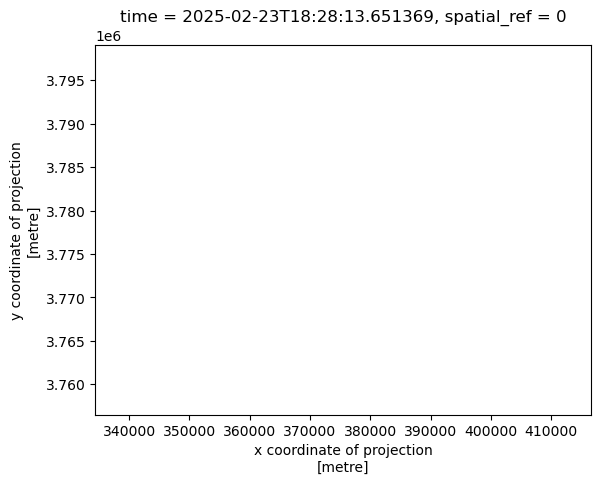

In [ ]:
# Select RGB variables, convert to data array, plot
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow()

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


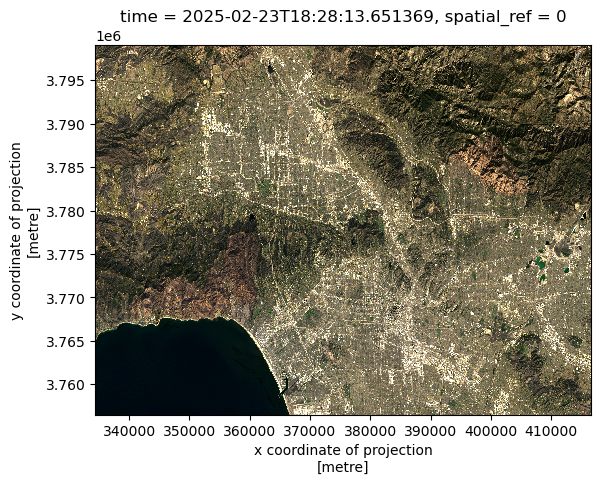

In [58]:
# Adjust the scale used for plotting the bands
landsat[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust=True)

In [47]:
# Find which bands have nan values 
for band in landsat:
    print(np.isnan(landsat[band]).any())


<xarray.DataArray 'red' ()> Size: 1B
array(False)
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
<xarray.DataArray 'green' ()> Size: 1B
array(True)
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
<xarray.DataArray 'blue' ()> Size: 1B
array(True)
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
<xarray.DataArray 'nir08' ()> Size: 1B
array(False)
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
<xarray.DataArray 'swir22' ()> Size: 1B
array(False)
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0


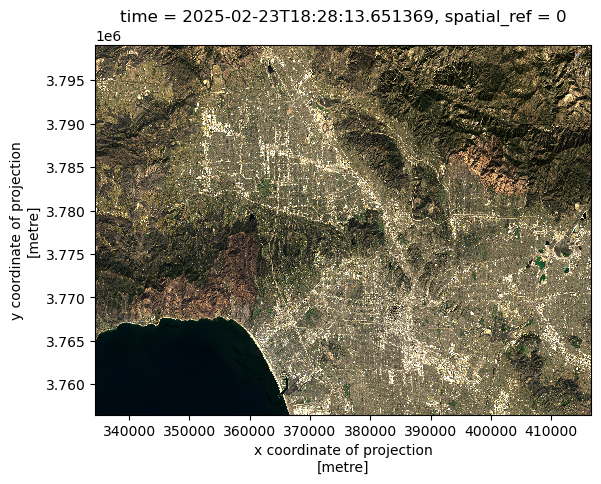

In [ ]:
# Fill nans with 0, plot without warnings
(landsat[['red', 'green', 'blue']].to_dataarray()
                                  .fillna(0)
                                  .plot.imshow(robust=True))

The initial map had multiple warnings and nothing showed up. The absence of any values on the plot was a result of the `robust` argument being set to `False` by default. By setting `Robust=True`, it adjusted the colormap range thereby allowing the plot to be displayed. Remaining warnings were resolved by replacing nan values in the `green` and `blue` bands with zeros. 

### False color image
Create a false color image by plotting the shortwave infrared (swir22), near-infrared, and red variables.

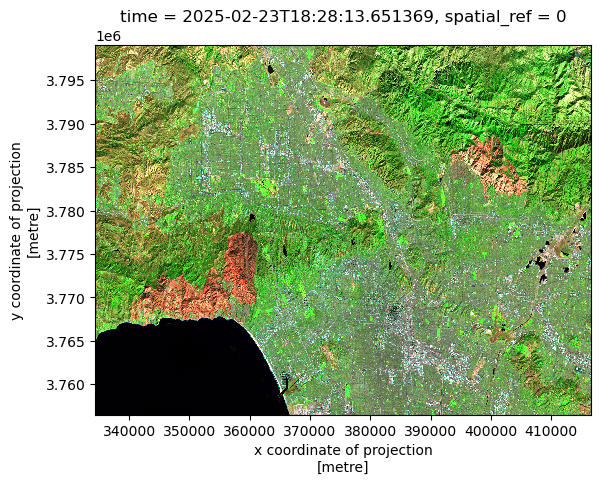

In [ ]:
# Create a false color image with 'swir22', 'nir08', and 'red'
(landsat[['swir22', 'nir08', 'red']].to_dataarray()
                                    .plot.imshow(robust=True))

### Map
Create a map showing the shortwave infrared/near-infrared/red false color image together with both fire perimeters.

In [68]:
# Reproject perimeter crs to match landsat
for df in eaton, palisades:
    df.to_crs(landsat.rio.crs, inplace=True)

assert landsat.rio.crs == eaton.crs
assert landsat.rio.crs == palisades.crs

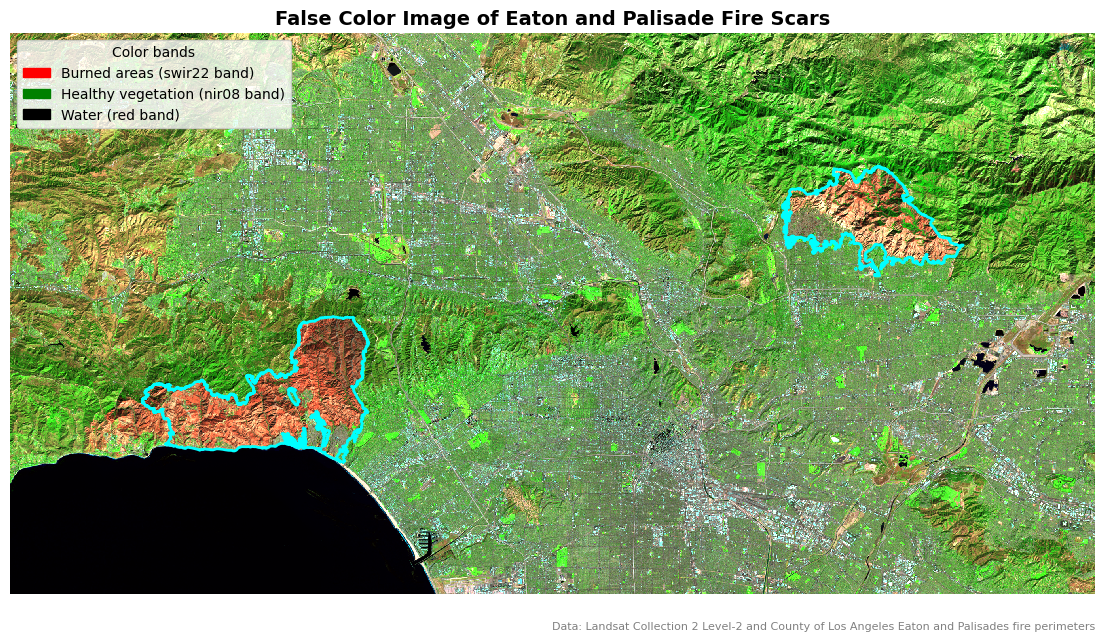

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(14, 12))
ax.axis('off')

# Add false color image as basemap 
(landsat[['swir22', 'nir08', 'red']].to_dataarray()
                                    .plot.imshow(ax=ax, robust=True))

# Make a legend describing the color bands 
key = [
    Patch(color='red', label='Burned areas (swir22 band)'),
    Patch(color='green', label='Healthy vegetation (nir08 band)'),
    Patch(color='black', label='Water (red band)'),
]
ax.legend(handles=key, title='Color bands', loc='upper left')

# Add fire perimeters
eaton.plot(ax=ax, facecolor='none', edgecolor='cyan', linewidth=2)
palisades.plot(ax=ax, facecolor='none', edgecolor='cyan', linewidth=2)

# Add annotation to identify each fire

# Add title
ax.set_title("False Color Image of Eaton and Palisade Fire Scars", fontsize=14, fontweight='bold')

# Add data sources
ax.annotate("Data: Landsat Collection 2 Level-2 and County of Los Angeles Eaton and Palisades fire perimeters",
            xy=(1, -.05), xycoords='axes fraction',  # Bottom-right corner of the axes
            ha='right', va='top', fontsize=8, color='gray')

# Display
plt.show()